# Porównanie FFNN i SOM na zbiorach Banknote Authentication i Adult

Sprawdzamy, jak sieć nadzorowana przewiduje klasy i jak mapa uczona bez etykiet organizuje te same dane. Aby odtworzyć wyniki w Google Colab, uruchom wszystkie komórki. Notebook korzysta z plików lokalnych, a w razie ich braku pobiera dane z UCI.

Źródła: [Banknote Authentication, Volker Lohweg](https://doi.org/10.24432/C55P57) i [Adult, Barry Becker i Ronny Kohavi](https://doi.org/10.24432/C5XW20).

In [1]:
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report, log_loss
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
UCI = 'https://archive.ics.uci.edu/ml/machine-learning-databases'
BANK_FEATURES = ['variance', 'skewness', 'curtosis', 'entropy']
ADULT_FEATURES = (
    'age workclass fnlwgt education education-num marital-status occupation '
    'relationship race sex capital-gain capital-loss hours-per-week native-country'
).split()
ADULT_NUMERIC = 'age fnlwgt education-num capital-gain capital-loss hours-per-week'.split()

def source(filename, directory):
    return Path(filename) if Path(filename).is_file() else f'{UCI}/{directory}/{filename}'

## Dane i preprocessing

**Banknote Authentication.** Zadanie polega na rozróżnianiu dwóch klas banknotów na podstawie czterech cech wyznaczonych z obrazów za pomocą transformaty falkowej. W wynikach używamy oznaczeń klas 0 i 1 z pliku UCI.

**Adult.** Przewidujemy, czy roczny dochód przekracza 50 tys. USD. Zbiór zawiera 6 cech liczbowych i 8 kategorycznych. Łączymy oba pliki Adult i wykonujemy własny podział, aby dla obu zbiorów użyć proporcji około 70/15/15.

Usuwamy powtórzenia pełnych rekordów przed podziałem. W Adult pytajnik oznacza brak danych. Brak w cesze kategorycznej otrzymuje własną kategorię, a one-hot encoding obsługuje również kategorie niewidziane podczas treningu. Cechy liczbowe standaryzujemy. Parametry skalowania i słownik kategorii dopasowujemy tylko na treningu. Podział jest stratyfikowany.

In [2]:
bank = pd.read_csv(source('data_banknote_authentication.txt', '00267'),
                   names=BANK_FEATURES + ['class'])
adult_options = dict(names=ADULT_FEATURES + ['class'], skipinitialspace=True,
                     na_values='?', comment='|')
adult = pd.concat([
    pd.read_csv(source('adult.data', 'adult'), **adult_options),
    pd.read_csv(source('adult.test', 'adult'), **adult_options)
], ignore_index=True)
adult['class'] = adult['class'].str.strip().str.rstrip('.')

def prepare(frame, numeric, labels):
    features = frame.drop(columns='class')
    categorical = features.columns.difference(numeric).tolist()
    print(f'Próbki: {len(frame):,} | Cechy: {features.shape[1]} '
          f'| Powtórzenia: {frame.duplicated().sum()}')
    display(frame['class'].value_counts().rename('liczba').to_frame().assign(
        udział=lambda counts: counts['liczba'] / len(frame)
    ))
    missing = features.isna().sum()
    print('Braki według cech:', missing[missing.gt(0)].to_dict())
    frame = frame.drop_duplicates().copy()
    if categorical:
        frame[categorical] = frame[categorical].fillna('(brak)')
    x = frame.drop(columns='class')
    y = frame['class'].map({value: index for index, value in enumerate(labels)}).to_numpy()
    x_train, x_rest, y_train, y_rest = train_test_split(
        x, y, test_size=0.30, stratify=y, random_state=SEED
    )
    x_val, x_test, y_val, y_test = train_test_split(
        x_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED
    )
    transform = ColumnTransformer([
        ('numeric', StandardScaler(), numeric),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical)
    ])
    transformed = [transform.fit_transform(x_train), transform.transform(x_val),
                   transform.transform(x_test)]
    splits = dict(zip(('train', 'val', 'test'), zip(
        [part.astype(np.float32) for part in transformed], [y_train, y_val, y_test]
    )))
    display(pd.DataFrame({
        name: pd.Series(target).value_counts().reindex([0, 1]).to_numpy()
        for name, (_, target) in splits.items()
    }, index=labels))
    print('Cechy po preprocessingu:', transformed[0].shape[1])
    return splits

datasets = {}
for name, frame, numeric, labels in [
    ('Banknote', bank, BANK_FEATURES, [0, 1]),
    ('Adult', adult, ADULT_NUMERIC, ['<=50K', '>50K'])
]:
    display(Markdown(f'### {name}'))
    datasets[name] = (prepare(frame, numeric, labels), [str(label) for label in labels])

### Banknote

Próbki: 1,372 | Cechy: 4 | Powtórzenia: 24


,liczba,udział
class,,
0,762,0.555394
1,610,0.444606


Braki według cech: {}


,train,val,test
0,516,111,111
1,427,91,92


Cechy po preprocessingu: 4


... (2 outputs left out)

,liczba,udział
class,,
<=50K,37155,0.760718
>50K,11687,0.239282


Braki według cech: {'workclass': 2799, 'occupation': 2809, 'native-country': 857}


,train,val,test
<=50K,25976,5566,5567
>50K,8177,1752,1752


Cechy po preprocessingu: 108


## Eksperyment bazowy FFNN

Dwie warstwy ukryte z ReLU (32 i 16 neuronów), wyjście sigmoidalne, log loss. Optymalizator Adam, learning rate 0,001, regularyzacja L2 0,0001, batch 128. Trenujemy do 60 epok i przywracamy model z najmniejszym log loss na zbiorze walidacyjnym. Próg klasyfikacji to 0,5. Test służy do końcowej oceny, a wykres loss pokazuje przebieg na treningu i walidacji.

### Banknote

Najlepsza epoka: 60 | Test accuracy: 0.9901


,precision,recall,f1-score,support
0,1.0000,0.9820,0.9909,111.0
1,0.9787,1.0000,0.9892,92.0
macro avg,0.9894,0.9910,0.9901,203.0
weighted avg,0.9904,0.9901,0.9902,203.0


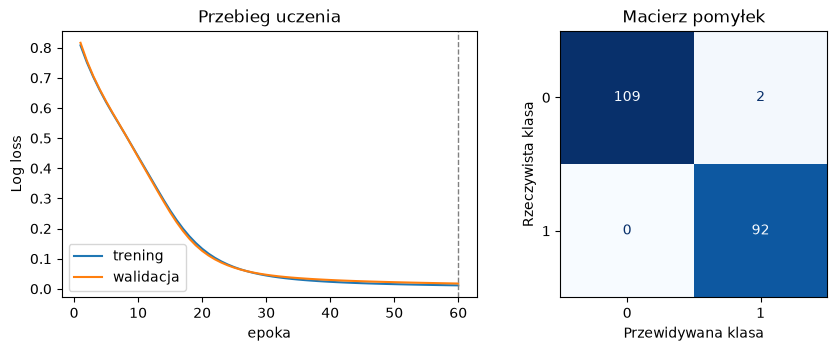

### Adult

Najlepsza epoka: 12 | Test accuracy: 0.8575


,precision,recall,f1-score,support
<=50K,0.8875,0.9307,0.9085,5567.0
>50K,0.7394,0.6250,0.6774,1752.0
macro avg,0.8134,0.7778,0.7930,7319.0
weighted avg,0.8520,0.8575,0.8532,7319.0


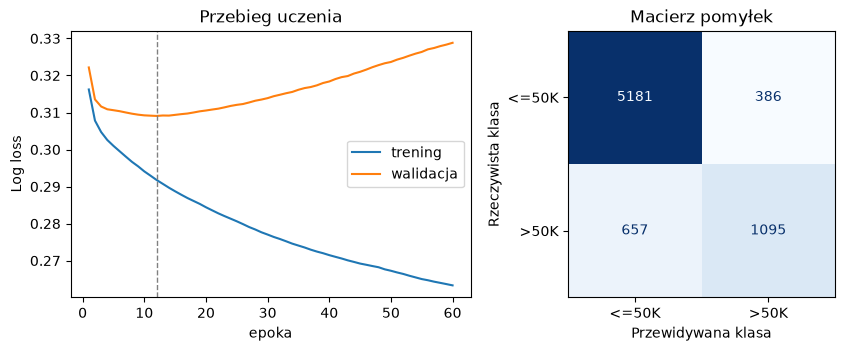

In [3]:
def fit_ffnn(splits):
    x_train, y_train = splits['train']
    x_val, y_val = splits['val']
    network = MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu',
                            solver='adam', learning_rate_init=0.001, alpha=0.0001,
                            batch_size=128, random_state=SEED)
    history = []
    best_loss = np.inf
    with threadpool_limits(limits=1, user_api='blas'):
        for epoch in range(1, 61):
            network.partial_fit(x_train, y_train, classes=[0, 1])
            train_loss = log_loss(y_train, network.predict_proba(x_train))
            val_loss = log_loss(y_val, network.predict_proba(x_val))
            history.append((epoch, train_loss, val_loss))
            if val_loss < best_loss:
                best_loss = val_loss
                best_epoch = epoch
                best_model = deepcopy(network)
    return best_model, best_epoch, pd.DataFrame(history, columns=['epoka', 'trening', 'walidacja'])

def report_ffnn(splits, labels, name):
    model, epoch, history = fit_ffnn(splits)
    x_test, y_test = splits['test']
    predicted = model.predict(x_test)
    report = classification_report(y_test, predicted, labels=[0, 1],
                                   target_names=labels, output_dict=True, zero_division=0)
    display(Markdown(f'### {name}'))
    print(f'Najlepsza epoka: {epoch} | Test accuracy: {accuracy_score(y_test, predicted):.4f}')
    display(pd.DataFrame(report).T.loc[labels + ['macro avg', 'weighted avg']].round(4))
    fig, (loss_axis, matrix_axis) = plt.subplots(1, 2, figsize=(9, 3.4), layout='constrained')
    history.set_index('epoka').plot(ax=loss_axis, ylabel='Log loss', title='Przebieg uczenia')
    loss_axis.axvline(epoch, color='gray', linestyle='--', linewidth=1)
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, display_labels=labels,
                                           ax=matrix_axis, cmap='Blues', colorbar=False)
    matrix_axis.set(xlabel='Przewidywana klasa', ylabel='Rzeczywista klasa', title='Macierz pomyłek')
    plt.show()
    return report

ffnn_results = {name: report_ffnn(splits, labels, name)
                for name, (splits, labels) in datasets.items()}

## Eksperyment bazowy SOM

Stosujemy prostokątną, dwuwymiarową siatkę o możliwie równych bokach. Robocza heurystyka to około $5\sqrt{n}$ neuronów, gdzie $n$ jest liczebnością treningu. Bok dobieramy jako $\operatorname{round}(\sqrt{5\sqrt{n}})$, aby uzyskać mapę kwadratową. Liczbę neuronów dobieramy osobno dla każdego zbioru.

Uczenie wsadowe trwa 30 epok. W każdej epoce losujemy bez zwracania do 4096 próbek treningowych. Każdy neuron przesuwa się w stronę średniej ważonej próbek, z wagami wyznaczonymi przez gaussowskie sąsiedztwo ich zwycięskich neuronów. Learning rate maleje od 0,7 do 0,2, a promień od boku siatki / 3 do 0,8. Prototypy inicjalizujemy losowymi rekordami treningowymi. Używamy odległości euklidesowej w przestrzeni cech po preprocessingu.

Na teście **quantization error (QE)** to średnia odległość do najbliższego neuronu (BMU). **Topographic error (TE)** to odsetek rekordów, dla których dwa najbliższe neurony nie stykają się bokiem. U-matrix pokazuje średnią odległość prototypu od sąsiadów w czterech kierunkach. Na mapie klas nanosimy większościową etykietę testowych próbek przypisanych do neuronu, a remisy oznaczamy osobno. Etykiety służą do interpretacji mapy po uczeniu.

### Banknote

Siatka: 12 × 12 | Test QE: 0.4054 | Test TE: 14.29%
Zajęte neurony: 94 | Neurony z obiema klasami: 0


,0,1
Wszystkie trafienia testowe,111,92


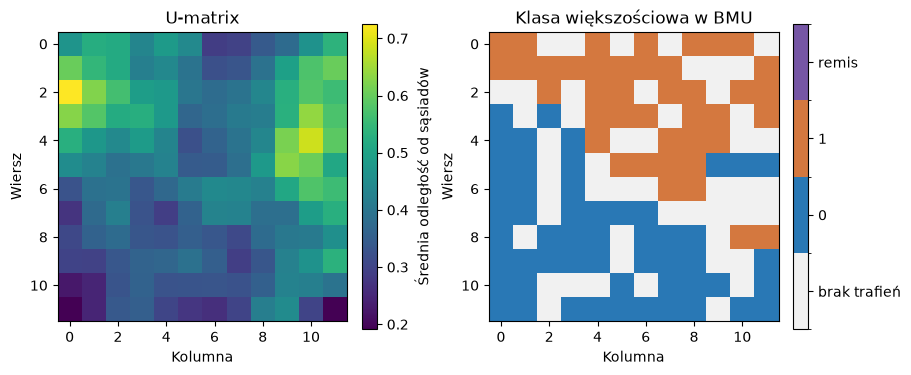

### Adult

Siatka: 30 × 30 | Test QE: 1.7985 | Test TE: 13.28%
Zajęte neurony: 814 | Neurony z obiema klasami: 347


,<=50K,>50K
Wszystkie trafienia testowe,5567,1752


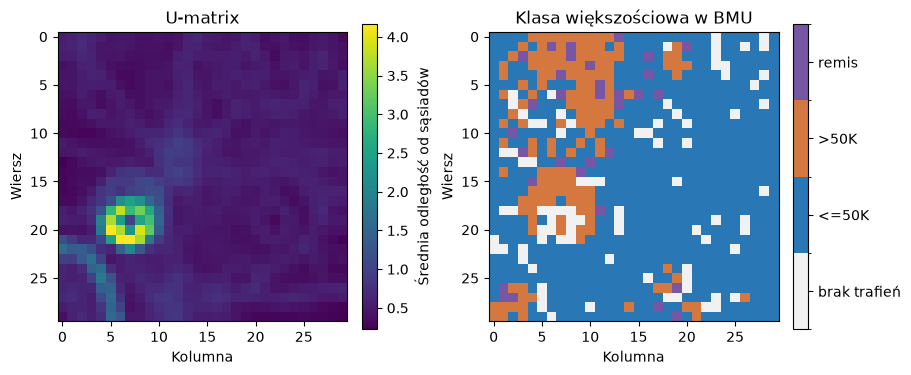

In [4]:
def squared_distances(samples, weights):
    return np.maximum(
        (samples ** 2).sum(axis=1, keepdims=True)
        + (weights ** 2).sum(axis=1) - 2 * samples @ weights.T, 0
    )

def fit_som(x_train):
    rng = np.random.default_rng(SEED)
    side = round(np.sqrt(5 * np.sqrt(len(x_train))))
    coordinates = np.indices((side, side)).reshape(2, -1).T
    offsets = coordinates[:, None] - coordinates[None, :]
    grid_distance = np.square(offsets).sum(axis=2)
    adjacent = grid_distance == 1
    weights = x_train[rng.choice(len(x_train), len(coordinates), replace=False)].copy()
    with threadpool_limits(limits=1, user_api='blas'):
        for rate, radius in zip(np.geomspace(0.7, 0.2, 30), np.geomspace(side / 3, 0.8, 30)):
            batch = x_train[rng.choice(len(x_train), min(4096, len(x_train)), replace=False)]
            bmu = squared_distances(batch, weights).argmin(axis=1)
            totals = np.zeros_like(weights)
            np.add.at(totals, bmu, batch)
            counts = np.bincount(bmu, minlength=len(weights)).astype(np.float32)
            neighborhood = np.exp(-grid_distance / (2 * radius ** 2)).astype(np.float32)
            mass = neighborhood @ counts
            targets = neighborhood @ totals / mass[:, None]
            weights += rate * (targets - weights)
    return weights, side, adjacent

def report_som(splits, labels, name):
    x_train, _ = splits['train']
    x_test, y_test = splits['test']
    weights, side, adjacent = fit_som(x_train)
    with threadpool_limits(limits=1, user_api='blas'):
        distances = squared_distances(x_test, weights)
    pairs = np.argpartition(distances, 1, axis=1)[:, :2]
    nearest = distances.argmin(axis=1)
    qe = np.linalg.norm(x_test - weights[nearest], axis=1).mean()
    te = (~adjacent[pairs[:, 0], pairs[:, 1]]).mean()

    neighbor_left, neighbor_right = np.where(adjacent)
    neighbor_distances = np.linalg.norm(weights[neighbor_left] - weights[neighbor_right], axis=1)
    u_matrix = np.bincount(neighbor_left, weights=neighbor_distances) / adjacent.sum(axis=1)

    hits = np.zeros((len(weights), 2), dtype=int)
    np.add.at(hits, (nearest, y_test), 1)
    occupied = hits.sum(axis=1) > 0
    mixed = (hits > 0).all(axis=1)
    majority = np.full(len(weights), -1)
    majority[occupied] = hits[occupied].argmax(axis=1)
    majority[mixed & (hits[:, 0] == hits[:, 1])] = 2

    display(Markdown(f'### {name}'))
    print(f'Siatka: {side} × {side} | Test QE: {qe:.4f} | Test TE: {te:.2%}')
    print(f'Zajęte neurony: {occupied.sum()} | Neurony z obiema klasami: {mixed.sum()}')
    display(pd.DataFrame(hits[occupied].sum(axis=0)[None, :], columns=labels,
                         index=['Wszystkie trafienia testowe']))
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
    heat = axes[0].imshow(u_matrix.reshape(side, side), cmap='viridis')
    fig.colorbar(heat, ax=axes[0], label='Średnia odległość od sąsiadów', shrink=0.8)
    cmap = ListedColormap(['#f1f1f1', '#2978b5', '#d4783f', '#7656a5'])
    classes = axes[1].imshow(majority.reshape(side, side), cmap=cmap,
                             norm=BoundaryNorm([-1.5, -.5, .5, 1.5, 2.5], cmap.N))
    legend = fig.colorbar(classes, ax=axes[1], ticks=[-1, 0, 1, 2], shrink=0.8)
    legend.ax.set_yticklabels(['brak trafień', *labels, 'remis'])
    for axis, title in zip(axes, ['U-matrix', 'Klasa większościowa w BMU']):
        axis.set(title=title, xlabel='Kolumna', ylabel='Wiersz')
    plt.show()
    return {'QE': qe, 'TE': te, 'udział mieszanych BMU': mixed.sum() / occupied.sum(),
            'zajęte BMU': occupied.sum()}

som_results = {name: report_som(splits, labels, name)
               for name, (splits, labels) in datasets.items()}

## Wyzwanie zestawu

Do uzupełnienia po ustaleniu treści pytania przypisanego grupie.

## Podsumowanie eksperymentu bazowego

Accuracy i F1 opisują jakość klasyfikacji FFNN. Dla Adult szczególnie ważne są recall i F1 dla dochodu powyżej 50 tys. USD, bo ta klasa jest rzadsza. SOM oceniamy za pomocą QE i TE oraz mapy trafień z testu. Wartości QE zależą od wymiarowości i reprezentacji danych, dlatego najlepiej porównywać je między wariantami jednego zbioru w tej samej przestrzeni cech.

In [5]:
summary = pd.DataFrame({
    name: {
        'FFNN accuracy': ffnn_results[name]['accuracy'],
        'FFNN macro F1': ffnn_results[name]['macro avg']['f1-score'],
        'FFNN recall klasy 1': ffnn_results[name][labels[1]]['recall'],
        **som_results[name]
    }
    for name, (_, labels) in datasets.items()
}).T
display(summary.round(4))

,FFNN accuracy,FFNN macro F1,FFNN recall klasy 1,QE,TE,udział mieszanych BMU,zajęte BMU
Banknote,0.9901,0.9901,1.000,0.4054,0.1429,0.0000,94.0
Adult,0.8575,0.7930,0.625,1.7985,0.1328,0.4263,814.0
